In [3]:
!pip install --upgrade keras

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 6.1 MB/s eta 0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 2.15.0
    Uninstalling keras-2.15.0:
      Successfully uninstalled keras-2.15.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.15.0 requires keras<2.16,>=2.15.0, but you have keras 3.0.4 which is incompatible.


In [1]:
import keras

print(keras.__version__)

3.0.4


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

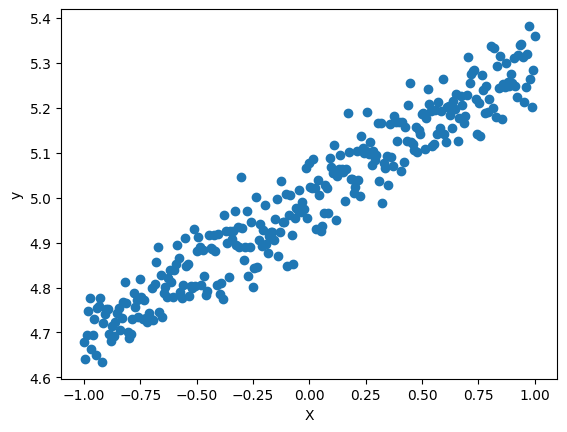

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Layer (type)                       ┃ Output Shape                  ┃     Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ dense (Dense)                      │ (None, 2)                     │           4 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dense_1 (Dense)                    │ (None, 1)                     │           3 │
└────────────────────────────────────┴───────────────────────────────┴─────────────┘

 Total params: 7 (28.00 B)

 Trainable params: 7 (28.00 B)

 Non-trainable params: 0 (0.00 B)

Training ....
Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.0000e+00 - loss: 22.8808 - val_accuracy: 0.0000e+00 - val_loss: 16.2022
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0000e+00 - loss: 14.2611 - val_accuracy: 0.0000e+00 - val_loss: 8.4320
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0000e+00 - loss: 6.8107 - val_accuracy: 0.0000e+00 - val_loss: 2.7133
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0000e+00 - loss: 1.9787 - val_accuracy: 0.0000e+00 - val_loss: 0.4724
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.0000e+00 - loss: 0.3210 - val_accuracy: 0.0000e+00 - val_loss: 0.0585
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.0000e+00 - loss: 0.0391 - val_accuracy: 0.0000e+00 - val_loss: 0.0093
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0000e+00 - loss: 0.0068 - val_accuracy: 0.0000e+00 - val_loss: 0.0035
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - ac

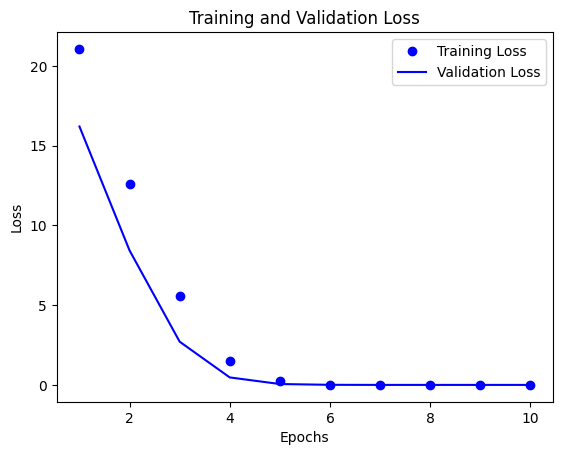


Testing ...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.0000e+00 - loss: 0.0020
Test Cost = [0.0020426076371222734, 0.0]

Hidden Layer ...
Weights= [[ 1.0091007 -1.3932675]] 
biases= [-1.307657  -1.0981393]

Output Layer ...
Weights= [[-1.3289509]
 [-1.182359 ]] 
biases= [1.9650916]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step


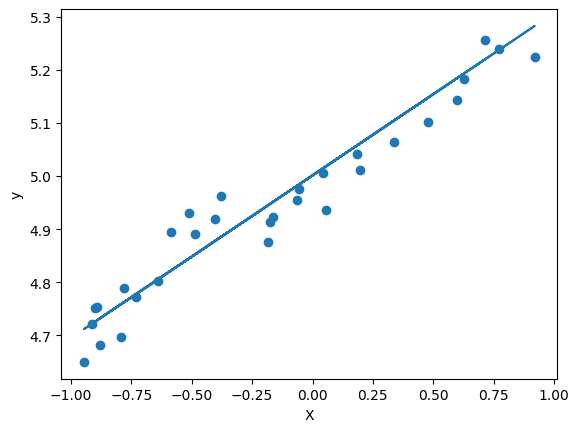

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from keras import Sequential
from keras.layers import Input, Dense

np.random.seed(10)  # 指定亂數種子
# 建立測試資料
X = np.linspace(-1, 1, 300)
np.random.shuffle(X)  # 使用亂數打亂資料
y = 0.3 * X + 5 + np.random.normal(0, 0.05, (300, ))
# 繪出資料的散佈圖
plt.scatter(X, y)
plt.xlabel("X")
plt.ylabel("y")

plt.show()

X_train, y_train = X[:270], y[:270]     # 訓練資料前270點
X_test, y_test = X[270:], y[270:]       # 測試資料後30點

# 建立Keras的Sequential模型
model = Sequential()
model.add(Input(shape=(1,)))
model.add(Dense(2))                     # 隱藏層 2個神經元
model.add(Dense(1))                     # 輸出層 1個神經元
# 編譯模型
model.compile(loss="mse", optimizer="sgd", metrics=["accuracy"])
model.summary()

# 訓練模型
print("Training ....")
history = model.fit(X_train, y_train, validation_split=0.2,
                    epochs=10, batch_size=30)

# 顯示訓練和驗證損失
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(loss)+1)

plt.plot(epochs, loss, "bo", label="Training Loss")
plt.plot(epochs, val_loss, "b", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()

# 測試模型
print("\nTesting ...")
cost = model.evaluate(X_test, y_test, batch_size=30)
print("Test Cost =", cost)
print("\nHidden Layer ...")
W, b = model.layers[0].get_weights()
print("Weights=", W, "\nbiases=", b)
print("\nOutput Layer ...")
W, b = model.layers[1].get_weights()
print("Weights=", W, "\nbiases=", b)

# 預測模型
y_pred = model.predict(X_test)
plt.scatter(X_test, y_test)
plt.plot(X_test, y_pred)
plt.xlabel("X")
plt.ylabel("y")

plt.show()
